# ResolveAI · Apoio comunitário nas primeiras 72 horas
**Projeto acadêmico CitizenTech — dados integralmente sintéticos.**

Andrei Oliveira de Sousa (RM 573373), Felipe Coelho da Fonseca (RM 572133),
Henrique Soares Pereira (RM 569898) e Luiz Felipe Lourenço da Silva (RM 572576).

O ResolveAI permite registrar, apoiar e acompanhar relatos urbanos, além de informar,
confirmar ou contestar resoluções. Este experimento trata exclusivamente da participação
dos moradores. Não há integração com prefeitura, SP156 ou execução de serviços públicos.

**Pergunta:** no momento da criação, a ocorrência receberá ao menos um apoio válido de
outra conta nas próximas 72 horas? Uma linha representa uma ocorrência. Classe 1 = sim;
classe 0 = não. O resultado só é conhecido após a janela completa. A previsão pode
fundamentar uma sugestão de divulgação ao autor; não altera status nem indica resolução.

Executar todas as células, na ordem, com Python 3.13 e `requirements.txt`.
O notebook lê o CSV entregue, verifica sua reprodução e exporta os pipelines usados pela API.

In [1]:
from pathlib import Path
import sys, hashlib, json, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

BASE = Path.cwd()
if not (BASE / "api_resolveai.py").exists() and (BASE / "ResolveAI_Entrega").is_dir():
    BASE = BASE / "ResolveAI_Entrega"
assert (BASE / "api_resolveai.py").exists(), "Abra o notebook na pasta da entrega."
assert sys.version_info[:2] == (3, 13), "Selecione o kernel Python 3.13."
VERSOES = {name: version(name) for name in
           ["numpy", "pandas", "scipy", "scikit-learn", "joblib"]}
print("Python", platform.python_version())
display(pd.Series(VERSOES, name="versão"))
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

Python 3.13.9


numpy            2.2.6
pandas           2.2.3
scipy           1.15.3
scikit-learn     1.6.1
joblib           1.5.1
Name: versão, dtype: object

## 1. Protocolo definido antes do treinamento

- Semente única **20261112**; nenhum ajuste do gerador a partir de métricas.
- Dois candidatos fixos: Regressão Logística (`C=1`, até 1000 iterações) e Random Forest
  (160 árvores, profundidade 7, mínimo de 20 amostras por folha). A Regressão Logística,
  apesar do nome, é usada para **classificação binária**.
- Referência: `DummyClassifier(strategy="prior")`, que prevê sempre a classe majoritária
  do treino e atribui a todos a mesma probabilidade, igual à proporção de classe 1 no treino.
- Critério de escolha entre os dois candidatos: **maior F1 macro na validação**;
  empate exato favorece a Regressão Logística por simplicidade. Limiar fixo de 0,5,
  sem otimização de hiperparâmetros ou limiar. A referência não substitui os candidatos.
- Treino: 01/01 a 14/05/2026. Validação: 18/05 a 24/06. Teste: 28/06 a 31/07.
  Os intervalos de 15–17/05 e 25–27/06 são descartados na modelagem para maturar os rótulos.
- Pré-processamento ajustado exclusivamente no treino. Sem retreino após a escolha:
  os pipelines avaliados serão exatamente os exportados. O teste final compara os três,
  mas não decide o vencedor nem altera configurações. Não existe meta de acurácia.

## 2. Hipóteses e geração sintética

São inventados: quatro regiões fictícias, quatro categorias, 200 contas por região,
96% de contas habilitadas, frequência de sessões, propensão a apoiar, efeito de categoria,
horário e congestionamento e a distribuição de atenção futura. Não há medição empírica
que sustente esses valores. O tamanho moderado mantém a execução rápida.

Simulamos 4.000 aberturas entre dezembro/2025 e julho/2026. Dezembro aquece os históricos
e não entra no CSV. Sessões de uso geram o contador de moradores distintos nos sete dias
anteriores. Cada ocorrência recebe exposições futuras sorteadas por Poisson; uma parcela
gera tentativas de apoio, com conta e instante próprios até 96 horas após a abertura.
Uma tentativa só é válida quando a conta é habilitada, diferente da autora e ainda não
apoiou a ocorrência. Só apoios válidos até 72 horas contam para o alvo.

A taxa histórica usa ocorrências da mesma região/categoria criadas nos 31 dias anteriores
**e com janela de 72 horas terminada antes da abertura atual** (aproximadamente 28 dias
de aberturas maduras). Suavização `(2 + positivos)/(4 + total)` evita taxas extremas com
poucos exemplos; na ausência de histórico retorna 0,5. Esses são resultados de eventos
passados, disponíveis no instante de previsão, mesmo quando pertencem a uma partição
anterior ou ao período já transcorrido da própria validação/teste. Simula-se uma operação
sequencial, com atualização dos contadores, sem atualizar os modelos.

Atenção futura latente e escolhas estocásticas dos moradores geram sobreposição natural:
atividade alta pode não gerar apoio e atividade baixa pode gerar. Não existem faixas
exclusivas por classe, troca de rótulos ou ruído acrescentado para reduzir acurácia.
Atencão, exposições, contas e eventos futuros são apenas internos ao simulador; não entram
no CSV de modelagem nem na API. Os eventos ficam em memória para auditoria.

In [2]:
SEMENTE = 20261112
CATEGORIAS = ["iluminacao", "limpeza", "vias", "acessibilidade"]
REGIOES = ["norte", "sul", "leste", "oeste"]
EXTRACAO = pd.Timestamp("2026-08-04 00:00:00")


def simular_ocorrencias(semente=SEMENTE):
    """Eventos sintéticos. Parâmetros definidos antes de observar métricas."""
    from bisect import bisect_left
    rng = np.random.default_rng(semente)
    inicio = pd.Timestamp("2025-12-01")  # dezembro aquece os históricos
    fim = pd.Timestamp("2026-08-01")
    # 200 contas por região; todas já existem antes do início da simulação.
    habilitadas = rng.random((4, 200)) < 0.96
    sessoes = [[] for _ in REGIOES]
    for dia in pd.date_range(inicio - pd.Timedelta(days=7), fim, freq="D"):
        for r, base in enumerate([5, 9, 14, 20]):
            movimento = rng.lognormal(-0.08, 0.4)  # oscilação diária não observada
            n = rng.poisson(base * movimento)
            for _ in range(n):
                t = dia + pd.Timedelta(seconds=int(rng.integers(0, 86400)))
                sessoes[r].append((t, int(rng.integers(200))))
    sessoes = [sorted(s) for s in sessoes]
    tempos_sessoes = [[t for t, _ in s] for s in sessoes]
    segundos = int((fim - inicio).total_seconds())
    instantes = np.sort(rng.choice(segundos, size=4000, replace=False))
    registros, eventos, auditoria = [], [], []
    fator_categoria = dict(iluminacao=1.3, limpeza=0.85, vias=1.05, acessibilidade=0.75)
    for i, offset in enumerate(instantes):
        t = inicio + pd.Timedelta(seconds=int(offset))
        r = int(rng.integers(4))
        regiao = REGIOES[r]
        categoria = str(rng.choice(CATEGORIAS))
        autor = int(rng.integers(200))
        limite7 = t - pd.Timedelta(days=7)
        limite31 = t - pd.Timedelta(days=31)
        lo = bisect_left(tempos_sessoes[r], limite7)
        hi = bisect_left(tempos_sessoes[r], t)
        ativos = len({a for ts, a in sessoes[r][lo:hi]})
        anteriores = [x for x in registros if x["regiao"] == regiao]
        proximas = sum(limite7 <= x["criada_em"] < t for x in anteriores)
        # Apenas rótulos cuja janela acabou ANTES da abertura atual.
        historico = [x for x in anteriores if x["categoria"] == categoria
                     and limite31 <= x["criada_em"]
                     and x["observacao_ate"] < t]
        taxa = (2 + sum(x["apoio_72h"] for x in historico)) / (4 + len(historico))
        janela = t + pd.Timedelta(hours=72)
        registro = dict(ocorrencia_id=f"SIM-{i:05d}", criada_em=t, observacao_ate=janela,
                        categoria=categoria, regiao=regiao, dia_semana=t.dayofweek,
                        hora_abertura=t.hour, moradores_ativos_7d=ativos,
                        taxa_apoio_anterior_28d=taxa, ocorrencias_regiao_7d=proximas)
        # Choque de atenção futuro: circulação e interesse não medidos no cadastro.
        # Não é ruído adicionado ao rótulo; afeta o processo gerador dos eventos.
        atencao = rng.lognormal(-0.5 * 0.7**2, 0.7)
        horario = 1.25 if 17 <= t.hour <= 22 else (0.8 if t.hour < 7 else 1.0)
        fim_semana = 1.15 if t.dayofweek >= 5 else 1.0
        exposicoes = rng.poisson((0.65 + ativos / 40) * fator_categoria[categoria]
                                * horario * fim_semana * atencao / (1 + proximas / 45))
        vistos, validos_72h, tentativas = set(), 0, []
        for _ in range(exposicoes):
            # Nem toda exposição gera uma tentativa de apoio.
            if rng.random() >= 0.72:
                continue
            conta = int(rng.integers(200))
            instante = t + pd.Timedelta(seconds=int(rng.integers(1, 96 * 3600 + 1)))
            tentativas.append((instante, conta))
        for instante, conta in sorted(tentativas):
            valido = conta != autor and bool(habilitadas[r, conta]) and conta not in vistos
            if valido:
                vistos.add(conta)
                validos_72h += int(instante <= janela)
            eventos.append(dict(ocorrencia_id=registro["ocorrencia_id"], autor=autor,
                                conta=conta, instante=instante, valido=valido,
                                habilitada=bool(habilitadas[r, conta])))
        # O rótulo fica armazenado como resultado futuro, separado das entradas.
        # O filtro historico acima controla quando esse resultado pode ser lido.
        registro["apoio_72h"] = int(validos_72h > 0) if janela <= EXTRACAO else np.nan
        registros.append(registro)
        auditoria.append(dict(ocorrencia_id=registro["ocorrencia_id"],
                              ultimo_historico=max((x["observacao_ate"] for x in historico), default=pd.NaT),
                              historico_n=len(historico)))
    base = pd.DataFrame(registros)
    base = base.loc[(base.criada_em >= "2026-01-01") & (base.observacao_ate <= EXTRACAO)].copy()
    base["apoio_72h"] = base.apoio_72h.astype("int64")
    return base.reset_index(drop=True), pd.DataFrame(eventos), pd.DataFrame(auditoria)

In [3]:
gerada, eventos, auditoria = simular_ocorrencias()
csv_path = BASE / "dados_resolveai.csv"
if not csv_path.exists():
    gerada.to_csv(csv_path, index=False, float_format="%.12g", date_format="%Y-%m-%dT%H:%M:%S")
dados = pd.read_csv(csv_path, parse_dates=["criada_em", "observacao_ate"])
pd.testing.assert_frame_equal(dados, gerada, check_exact=False, atol=1e-11, rtol=1e-10)
CSV_SHA256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
print(f"{len(dados):,} ocorrências no CSV | SHA-256: {CSV_SHA256}")
print("Extração simulada:", EXTRACAO, "(horário local de São Paulo; todas as datas são locais)")
display(dados.head())

3,458 ocorrências no CSV | SHA-256: 2bc1b471de06354258c134684c7c13a8ce86bff25f8d0cca921d9d149df5ca9c
Extração simulada: 2026-08-04 00:00:00 (horário local de São Paulo; todas as datas são locais)


,ocorrencia_id,criada_em,observacao_ate,categoria,regiao,dia_semana,hora_abertura,moradores_ativos_7d,taxa_apoio_anterior_28d,ocorrencias_regiao_7d,apoio_72h
0,SIM-00542,2026-01-01 00:35:58,2026-01-04 00:35:58,vias,sul,3,0,58,0.363636,24,0
1,SIM-00543,2026-01-01 03:17:09,2026-01-04 03:17:09,vias,sul,3,3,57,0.363636,23,0
2,SIM-00544,2026-01-01 06:59:51,2026-01-04 06:59:51,vias,leste,3,6,71,0.666667,32,0
3,SIM-00545,2026-01-01 07:05:53,2026-01-04 07:05:53,limpeza,oeste,3,7,118,0.425000,25,1
4,SIM-00546,2026-01-01 07:12:10,2026-01-04 07:12:10,acessibilidade,oeste,3,7,118,0.531250,26,1


## 3. Dicionário dos dados e seleção de entradas

| Coluna | Tipo e unidade | Disponibilidade / significado |
|---|---|---|
| ocorrencia_id | texto, identificador sintético | Auditoria; nunca é entrada |
| criada_em | data/hora local, ISO 8601 | Abertura; ordenação e partição, nunca entrada direta |
| observacao_ate | data/hora local | Abertura + 72 h; auditoria do alvo, nunca entrada |
| categoria | texto nominal | iluminacao, limpeza, vias ou acessibilidade, informada na abertura |
| regiao | texto nominal | norte, sul, leste ou oeste, região fictícia aproximada |
| dia_semana | inteiro, 0–6 | Segunda = 0, domingo = 6; derivado da abertura |
| hora_abertura | inteiro, 0–23 h | Hora local de abertura |
| moradores_ativos_7d | inteiro, contas distintas, 0–200 | Sessões na região em [abertura − 7 dias, abertura) |
| taxa_apoio_anterior_28d | real, proporção 0–1 | Taxa suavizada de apoio em relatos semelhantes já maduros |
| ocorrencias_regiao_7d | inteiro, ocorrências | Aberturas na região nos 7 dias anteriores, exclui a atual |
| apoio_72h | inteiro binário | Alvo futuro; 1 = ao menos um apoio válido em 72 h, 0 = nenhum |

As sete entradas representam contexto disponível na abertura e competição por atenção.
Contamos relatos recentes, sem inferir se foram resolvidos. Não usamos foto, descrição,
identidade, localização exata, apoios futuros, status, tempo até apoio ou fatores latentes.
Hora e dia são tratados como categorias: isso evita presumir uma relação linear entre
domingo/segunda ou 23h/0h. Contadores e taxa são padronizados para a Regressão Logística;
o mesmo transformador é usado na floresta para manter um pipeline simples e consistente.

In [4]:
CAT = ["categoria", "regiao", "dia_semana", "hora_abertura"]
NUM = ["moradores_ativos_7d", "taxa_apoio_anterior_28d", "ocorrencias_regiao_7d"]
FEATURES = ["categoria", "regiao", "dia_semana", "hora_abertura",
            "moradores_ativos_7d", "taxa_apoio_anterior_28d", "ocorrencias_regiao_7d"]
assert not dados.isna().any().any()
assert not dados.duplicated().any() and dados.ocorrencia_id.is_unique
assert dados.criada_em.is_monotonic_increasing
assert (dados.observacao_ate - dados.criada_em).eq(pd.Timedelta(hours=72)).all()
assert dados.observacao_ate.le(EXTRACAO).all()
assert set(dados.apoio_72h) == {0, 1}
assert set(dados.categoria) == set(CATEGORIAS) and set(dados.regiao) == set(REGIOES)
assert dados.dia_semana.eq(dados.criada_em.dt.dayofweek).all()
assert dados.hora_abertura.eq(dados.criada_em.dt.hour).all()
for col in ["dia_semana", "hora_abertura", "moradores_ativos_7d", "ocorrencias_regiao_7d", "apoio_72h"]:
    assert pd.api.types.is_integer_dtype(dados[col])
assert dados.dia_semana.between(0, 6).all() and dados.hora_abertura.between(0, 23).all()
assert dados.moradores_ativos_7d.between(0, 200).all()
assert dados.ocorrencias_regiao_7d.between(0, 1000).all()
assert dados.taxa_apoio_anterior_28d.between(0, 1).all()
audit = dados.merge(auditoria, on="ocorrencia_id", validate="one_to_one")
assert (audit.ultimo_historico.isna() | (audit.ultimo_historico < audit.criada_em)).all()
ev = eventos.merge(dados[["ocorrencia_id", "criada_em", "observacao_ate"]], on="ocorrencia_id")
aceitos = ev.loc[ev.valido & ev.instante.le(ev.observacao_ate)]
assert (ev.instante > ev.criada_em).all()
assert (aceitos.conta != aceitos.autor).all() and aceitos.habilitada.all()
assert not aceitos.duplicated(["ocorrencia_id", "conta"]).any()
rotulo_auditado = dados.ocorrencia_id.isin(aceitos.ocorrencia_id).astype(int)
assert rotulo_auditado.eq(dados.apoio_72h).all()
print("Tipos, ausências, duplicidades, limites, temporalidade histórica e alvo por eventos: OK")
display(pd.DataFrame({"tipo": dados.dtypes.astype(str), "ausentes": dados.isna().sum(),
                      "distintos": dados.nunique()}))
display(dados[NUM].describe().round(3))

Tipos, ausências, duplicidades, limites, temporalidade histórica e alvo por eventos: OK


,tipo,ausentes,distintos
ocorrencia_id,object,0,3458
criada_em,datetime64[ns],0,3458
observacao_ate,datetime64[ns],0,3458
categoria,object,0,4
regiao,object,0,4
dia_semana,int64,0,7
hora_abertura,int64,0,24
moradores_ativos_7d,int64,0,116
taxa_apoio_anterior_28d,float64,0,305
ocorrencias_regiao_7d,int64,0,35


,moradores_ativos_7d,taxa_apoio_anterior_28d,ocorrencias_regiao_7d
count,3458.000,3458.000,3458.00
mean,65.423,0.439,28.48
std,26.963,0.124,5.05
min,14.000,0.143,12.00
25%,41.000,0.343,25.00
50%,64.000,0.436,28.00
75%,87.000,0.542,32.00
max,129.000,0.778,46.00


## 4. Separação temporal e exploração do treino

O teste permanece reservado. As análises que poderiam orientar decisões de modelagem
usam somente treino. Registros dos intervalos de maturação permanecem no CSV para
transparência, mas não são usados para ajustar ou pontuar os classificadores.

,conjunto,n,abertura_min,abertura_max,rotulo_conhecido_ate
0,treino,2215,2026-01-01 00:35:58,2026-05-14 19:49:43,2026-05-17 19:49:43
1,validacao,598,2026-05-18 00:09:56,2026-06-24 21:52:04,2026-06-27 21:52:04
2,teste,555,2026-06-28 00:35:12,2026-07-31 20:17:01,2026-08-03 20:17:01


Registros nos intervalos descartados: 90


,n
classe,
0,1272
1,943


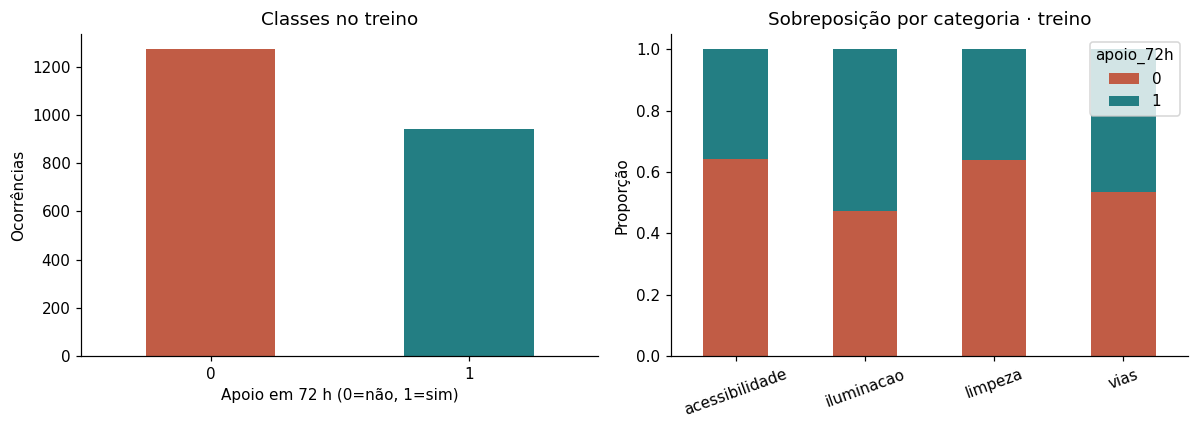

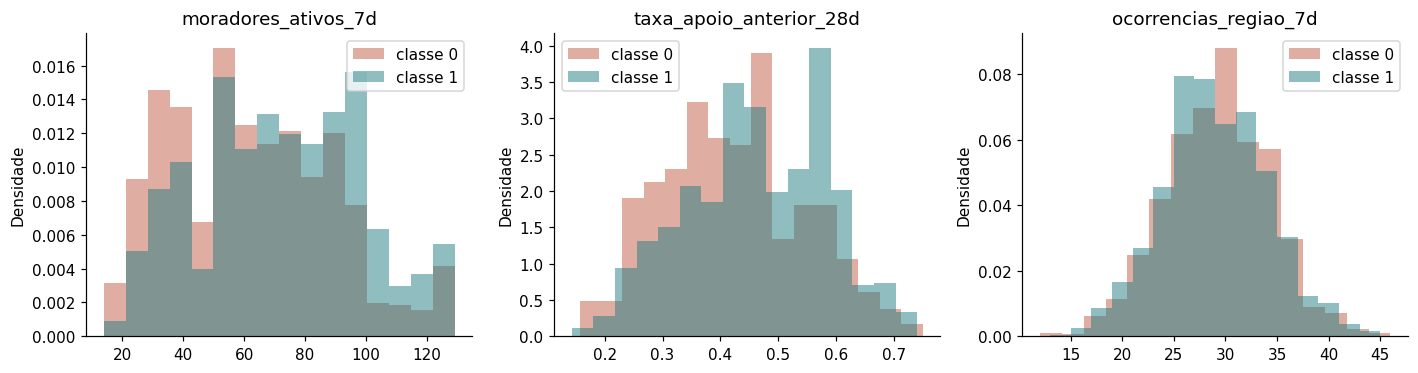

apoio_72h,0,1
moradores_ativos_7d,,
"(13.999, 44.0]",0.686,0.314
"(44.0, 65.0]",0.613,0.387
"(65.0, 87.0]",0.550,0.450
"(87.0, 129.0]",0.442,0.558


Alta atividade sem apoio: 252
Baixa atividade com apoio: 177
Grupos com pelo menos 5 relatos semelhantes e ambos os resultados: 117


,aberturas,proporcao_apoio
criada_em,,
2026-01-01,502,0.418
2026-02-01,480,0.410
2026-03-01,494,0.431
2026-04-01,514,0.432
2026-05-01,225,0.449


In [5]:
treino = dados.loc[dados.criada_em < "2026-05-15"].copy()
validacao = dados.loc[(dados.criada_em >= "2026-05-18") & (dados.criada_em < "2026-06-25")].copy()
teste = dados.loc[dados.criada_em >= "2026-06-28"].copy()
partes = {"treino": treino, "validacao": validacao, "teste": teste}
ids = [set(frame.ocorrencia_id) for frame in partes.values()]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2])
assert treino.observacao_ate.max() < validacao.criada_em.min()
assert validacao.observacao_ate.max() < teste.criada_em.min()
display(pd.DataFrame([dict(conjunto=name, n=len(frame), abertura_min=frame.criada_em.min(),
                          abertura_max=frame.criada_em.max(), rotulo_conhecido_ate=frame.observacao_ate.max())
                      for name, frame in partes.items()]))
print("Registros nos intervalos descartados:", len(dados) - sum(map(len, partes.values())))
display(treino.apoio_72h.value_counts().sort_index().rename_axis("classe").to_frame("n"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
treino.apoio_72h.value_counts().sort_index().plot.bar(ax=axes[0], color=["#c15c45", "#237e83"], rot=0)
axes[0].set(title="Classes no treino", xlabel="Apoio em 72 h (0=não, 1=sim)", ylabel="Ocorrências")
pd.crosstab(treino.categoria, treino.apoio_72h, normalize="index").plot.bar(
    stacked=True, ax=axes[1], color=["#c15c45", "#237e83"], rot=20)
axes[1].set(title="Sobreposição por categoria · treino", ylabel="Proporção", xlabel="")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, NUM):
    for label, color in [(0, "#c15c45"), (1, "#237e83")]:
        ax.hist(treino.loc[treino.apoio_72h == label, col], bins=16, alpha=.5,
                density=True, label=f"classe {label}", color=color)
    ax.set(title=col, ylabel="Densidade"); ax.legend()
plt.tight_layout(); plt.show()
faixas = pd.qcut(treino.moradores_ativos_7d, 4, duplicates="drop")
display(pd.crosstab(faixas, treino.apoio_72h, normalize="index").round(3))
q25, q75 = treino.moradores_ativos_7d.quantile([.25, .75])
print("Alta atividade sem apoio:", len(treino.loc[(treino.moradores_ativos_7d >= q75) & treino.apoio_72h.eq(0)]))
print("Baixa atividade com apoio:", len(treino.loc[(treino.moradores_ativos_7d <= q25) & treino.apoio_72h.eq(1)]))
# Contextos parecidos, agrupados por categoria, região e faixas dos dois contadores.
parecidos = treino.assign(ativos_faixa=(treino.moradores_ativos_7d // 10),
                          relatos_faixa=(treino.ocorrencias_regiao_7d // 10))
grupos = parecidos.groupby(["categoria", "regiao", "ativos_faixa", "relatos_faixa"]).apoio_72h.agg(["size", "nunique"])
print("Grupos com pelo menos 5 relatos semelhantes e ambos os resultados:",
      ((grupos["size"] >= 5) & (grupos["nunique"] == 2)).sum())
mensal = treino.set_index("criada_em").resample("MS").apoio_72h.agg(["count", "mean"])
display(mensal.rename(columns={"count": "aberturas", "mean": "proporcao_apoio"}).round(3))

As distribuições têm interseção e os contextos aproximados podem ter ambos os resultados.
Essa inspeção é descritiva: não prova realismo nem garante que não haja padrões artificiais.
Cada ocorrência compartilha sessões e históricos com outras; as linhas não são observações
independentes do mundo real. A divisão temporal representa previsão de aberturas futuras
na mesma comunidade simulada, não transferência para uma nova cidade ou região.

## 5. Pipelines e treinamento

One-hot para variáveis categóricas (`handle_unknown="ignore"`) e padronização das numéricas.
A API limita os domínios aceitos. Os dados passaram pela checagem de ausência, portanto
não é necessária imputação. Nenhum `fit` usa validação ou teste. As configurações são
modestas, fixadas no protocolo; a floresta é regularizada por profundidade e tamanho de folha.

In [6]:
def pipeline(classificador):
    preparacao = ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("numericas", StandardScaler(), NUM)
    ])
    return Pipeline([("preparacao", preparacao), ("classificador", classificador)])

modelos = {
    "referencia_dummy": pipeline(DummyClassifier(strategy="prior")),
    "regressao_logistica": pipeline(LogisticRegression(C=1.0, max_iter=1000, random_state=SEMENTE)),
    "random_forest": pipeline(RandomForestClassifier(n_estimators=160, max_depth=7,
                              min_samples_leaf=20, random_state=SEMENTE, n_jobs=1))
}
for nome, modelo in modelos.items():
    modelo.fit(treino[FEATURES], treino.apoio_72h)
    print("Treinado:", nome)

def avaliar(modelo, frame):
    y = frame.apoio_72h
    previsto = modelo.predict(frame[FEATURES])
    prob = modelo.predict_proba(frame[FEATURES])[:, 1]
    return dict(acuracia=accuracy_score(y, previsto), f1_macro=f1_score(y, previsto, average="macro"),
                brier=brier_score_loss(y, prob)), previsto, prob

metricas_val = pd.DataFrame({nome: avaliar(m, validacao)[0] for nome, m in modelos.items()}).T
display(metricas_val.round(4))
candidatos = ["regressao_logistica", "random_forest"]
escolhido = max(candidatos, key=lambda nome: metricas_val.loc[nome, "f1_macro"])
delta_val = abs(metricas_val.loc[candidatos[0], "f1_macro"] - metricas_val.loc[candidatos[1], "f1_macro"])
display(Markdown(f"**Escolhido pela validação: {escolhido}.** Diferença absoluta de F1 macro "
                 f"entre candidatos: {delta_val:.4f}. "
                 + ("A diferença é pequena em magnitude (< 0,02); não há evidência de superioridade geral."
                    if delta_val < .02 else "A diferença observada vale para esta simulação e este corte temporal.")))
if metricas_val.loc[escolhido, "f1_macro"] <= metricas_val.loc["referencia_dummy", "f1_macro"]:
    print("Atenção: o candidato escolhido não superou a referência em F1 macro na validação.")

Treinado: referencia_dummy
Treinado: regressao_logistica


Treinado: random_forest


,acuracia,f1_macro,brier
referencia_dummy,0.5669,0.3618,0.2456
regressao_logistica,0.6171,0.5715,0.2350
random_forest,0.5853,0.5398,0.2364


**Escolhido pela validação: regressao_logistica.** Diferença absoluta de F1 macro entre candidatos: 0.0317. A diferença observada vale para esta simulação e este corte temporal.

## 6. Avaliação final no teste reservado

A escolha está encerrada. Avaliamos todos os modelos sem modificar parâmetros, limiar,
dados ou pré-processamento. Acurácia é a proporção de acertos; precisão de uma classe
mede a correção das previsões dessa classe; recall mede a fração dos exemplos daquela
classe encontrados. F1 combina precisão e recall, e F1 macro dá peso igual às classes.
Brier é o erro quadrático médio das probabilidades em relação ao alvo: menor é melhor.
Isso não equivale, isoladamente, a demonstrar calibração.

,acuracia,f1_macro,brier
referencia_dummy,0.5586,0.3584,0.2468
regressao_logistica,0.6126,0.5879,0.2360
random_forest,0.6360,0.5948,0.2327



 referencia_dummy


,precision,recall,f1-score,support
0: sem apoio,0.5586,1.0000,0.7168,310.0000
1: com apoio,0.0000,0.0000,0.0000,245.0000
accuracy,0.5586,0.5586,0.5586,0.5586
macro avg,0.2793,0.5000,0.3584,555.0000
weighted avg,0.3120,0.5586,0.4004,555.0000



 regressao_logistica


,precision,recall,f1-score,support
0: sem apoio,0.6247,0.7677,0.6889,310.0000
1: com apoio,0.5862,0.4163,0.4869,245.0000
accuracy,0.6126,0.6126,0.6126,0.6126
macro avg,0.6054,0.5920,0.5879,555.0000
weighted avg,0.6077,0.6126,0.5997,555.0000



 random_forest


,precision,recall,f1-score,support
0: sem apoio,0.6280,0.8548,0.7240,310.000
1: com apoio,0.6617,0.3592,0.4656,245.000
accuracy,0.6360,0.6360,0.6360,0.636
macro avg,0.6448,0.6070,0.5948,555.000
weighted avg,0.6428,0.6360,0.6100,555.000


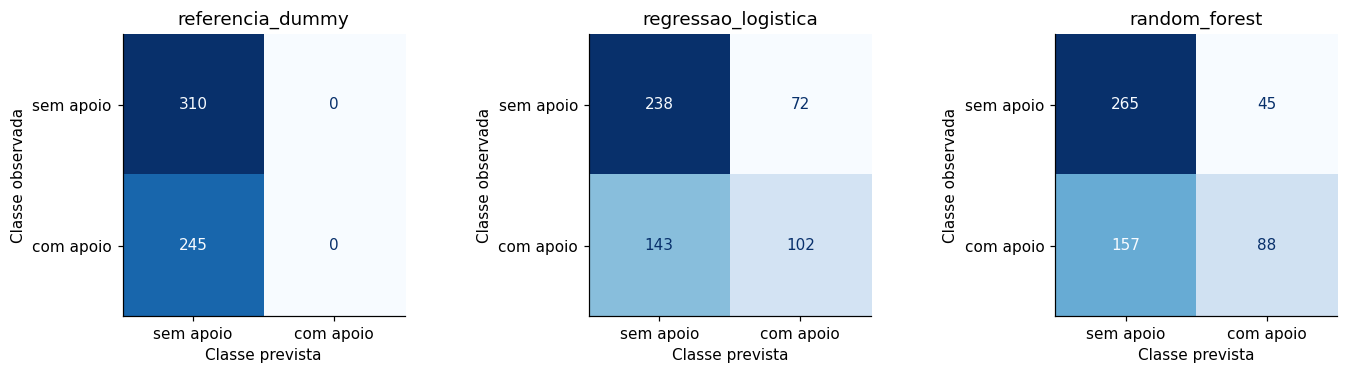

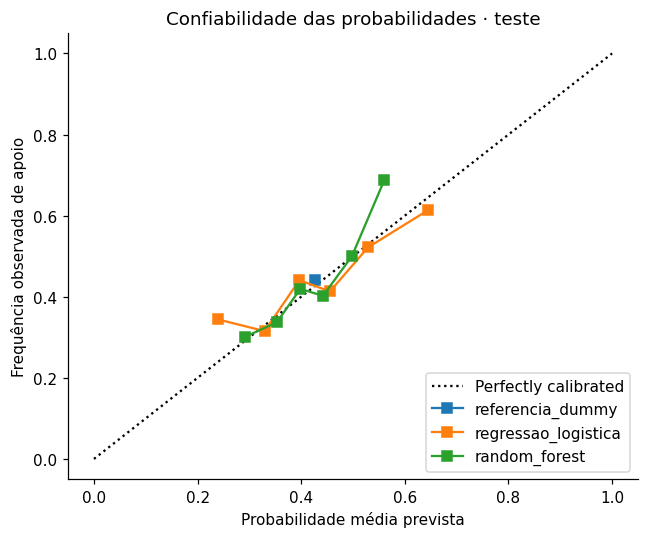

,conjunto,n,proporcao_apoio
0,treino,2215,0.4257
1,validacao,598,0.4331
2,teste,555,0.4414


In [7]:
resultados = {nome: avaliar(m, teste) for nome, m in modelos.items()}
metricas_teste = pd.DataFrame({nome: result[0] for nome, result in resultados.items()}).T
display(metricas_teste.round(4))
for nome, (_, previsto, _) in resultados.items():
    print("\n", nome)
    display(pd.DataFrame(classification_report(teste.apoio_72h, previsto, labels=[0, 1],
            target_names=["0: sem apoio", "1: com apoio"], output_dict=True, zero_division=0)).T.round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (nome, (_, previsto, _)) in zip(axes, resultados.items()):
    ConfusionMatrixDisplay.from_predictions(teste.apoio_72h, previsto, labels=[0, 1],
        display_labels=["sem apoio", "com apoio"], ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe observada")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 5))
for nome, (_, _, prob) in resultados.items():
    CalibrationDisplay.from_predictions(teste.apoio_72h, prob, n_bins=6,
        strategy="quantile", name=nome, ax=ax)
ax.set(title="Confiabilidade das probabilidades · teste", xlabel="Probabilidade média prevista",
       ylabel="Frequência observada de apoio")
plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(conjunto=nome, n=len(frame), proporcao_apoio=frame.apoio_72h.mean())
                      for nome, frame in partes.items()]).round(4))

No teste, o maior F1 macro entre os candidatos foi de **random_forest**. A distância entre eles foi **0.0070**. É uma diferença pequena em magnitude (< 0,02), sem teste de significância. A inversão de ordem em relação à validação, se ocorrer, evidencia incerteza entre períodos; não autoriza trocar a escolha após consultar o teste.

O candidato escolhido na validação foi **regressao_logistica**. No teste: F1 macro **0.5879**, acurácia **0.6126**, Brier **0.2360**. Diferença de F1 macro para a referência: **+0.2295**. A ordem no teste não muda a seleção feita antes.

Ocorreram **72 falsos positivos**: previu-se apoio que não veio. A sugestão de divulgação poderia deixar de aparecer para alguém que precisava. Houve **143 falsos negativos**: previu-se ausência de apoio, mas ele veio. O autor poderia receber uma sugestão de compartilhamento desnecessária. Acertos: 238 sem apoio e 102 com apoio. Os custos foram descritos qualitativamente; não há estimativa econômica ou social medida.

,categoria,regiao,dia_semana,hora_abertura,moradores_ativos_7d,taxa_apoio_anterior_28d,ocorrencias_regiao_7d,apoio_72h,previsto
2904,vias,norte,6,4,26,0.448276,21,1,0
2905,iluminacao,leste,6,4,78,0.538462,19,0,1
2908,limpeza,sul,6,9,60,0.303030,40,1,0
2909,iluminacao,sul,6,9,60,0.481481,41,1,0
2912,limpeza,oeste,6,17,104,0.580645,27,0,1
2915,limpeza,leste,6,21,76,0.400000,20,1,0
2922,iluminacao,norte,0,6,22,0.322581,19,1,0
2928,iluminacao,sul,0,12,61,0.464286,39,1,0
2931,acessibilidade,sul,0,15,62,0.363636,42,1,0
2939,acessibilidade,oeste,1,8,107,0.410256,26,1,0


,entrada,queda_media_f1_macro,desvio_entre_repeticoes
6,ocorrencias_regiao_7d,-0.0057,0.0029
5,taxa_apoio_anterior_28d,-0.0011,0.0032
1,regiao,0.0017,0.0036
2,dia_semana,0.0018,0.0087
3,hora_abertura,0.0350,0.0163
0,categoria,0.0401,0.0106
4,moradores_ativos_7d,0.0617,0.0155


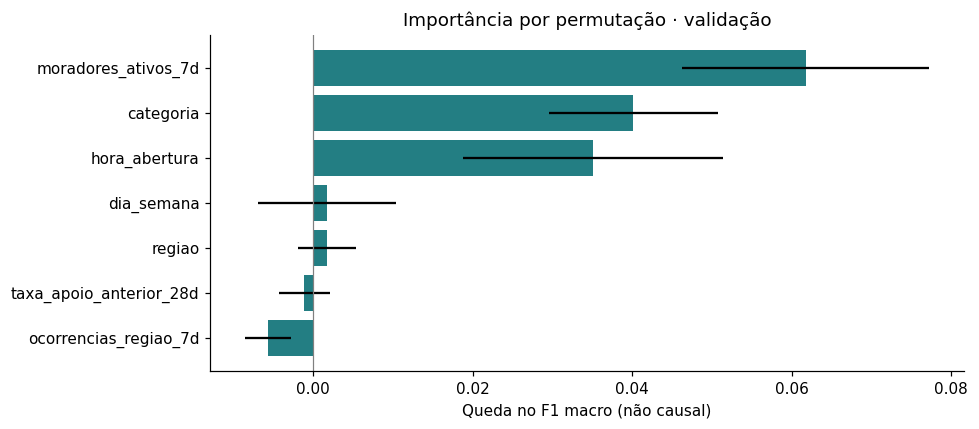

In [8]:
prev = resultados[escolhido][1]
tn, fp, fn, tp = confusion_matrix(teste.apoio_72h, prev, labels=[0, 1]).ravel()
delta_teste = metricas_teste.loc[escolhido, "f1_macro"] - metricas_teste.loc["referencia_dummy", "f1_macro"]
melhor_no_teste = metricas_teste.loc[candidatos, "f1_macro"].idxmax()
distancia_teste = abs(metricas_teste.loc[candidatos[0], "f1_macro"] - metricas_teste.loc[candidatos[1], "f1_macro"])
display(Markdown(f"No teste, o maior F1 macro entre os candidatos foi de **{melhor_no_teste}**. "
    f"A distância entre eles foi **{distancia_teste:.4f}**. "
    + ("É uma diferença pequena em magnitude (< 0,02), sem teste de significância. " if distancia_teste < .02 else "")
    + "A inversão de ordem em relação à validação, se ocorrer, evidencia incerteza entre períodos; "
    "não autoriza trocar a escolha após consultar o teste."))
display(Markdown(f"O candidato escolhido na validação foi **{escolhido}**. No teste: "
    f"F1 macro **{metricas_teste.loc[escolhido, 'f1_macro']:.4f}**, acurácia "
    f"**{metricas_teste.loc[escolhido, 'acuracia']:.4f}**, Brier "
    f"**{metricas_teste.loc[escolhido, 'brier']:.4f}**. Diferença de F1 macro para a referência: "
    f"**{delta_teste:+.4f}**. A ordem no teste não muda a seleção feita antes.\n\n"
    f"Ocorreram **{fp} falsos positivos**: previu-se apoio que não veio. A sugestão de divulgação "
    f"poderia deixar de aparecer para alguém que precisava. Houve **{fn} falsos negativos**: "
    f"previu-se ausência de apoio, mas ele veio. O autor poderia receber uma sugestão de "
    f"compartilhamento desnecessária. Acertos: {tn} sem apoio e {tp} com apoio. "
    "Os custos foram descritos qualitativamente; não há estimativa econômica ou social medida."))
erros = teste.loc[teste.apoio_72h.to_numpy() != prev, FEATURES + ["apoio_72h"]].copy()
erros["previsto"] = prev[teste.apoio_72h.to_numpy() != prev]
display(erros.head(10))
# Interpretação na validação, sem usar importâncias para ajustar o modelo.
importance = permutation_importance(modelos[escolhido], validacao[FEATURES], validacao.apoio_72h,
                                    scoring="f1_macro", n_repeats=5, random_state=SEMENTE, n_jobs=1)
importancias = pd.DataFrame({"entrada": FEATURES, "queda_media_f1_macro": importance.importances_mean,
                            "desvio_entre_repeticoes": importance.importances_std}).sort_values("queda_media_f1_macro")
display(importancias.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(importancias.entrada, importancias.queda_media_f1_macro,
        xerr=importancias.desvio_entre_repeticoes, color="#237e83")
ax.axvline(0, color="gray", lw=.8)
ax.set(title="Importância por permutação · validação", xlabel="Queda no F1 macro (não causal)")
plt.tight_layout(); plt.show()

## 7. Limitações e uso responsável no aplicativo

O experimento verifica um pipeline sobre um mundo inventado. Seus resultados não
demonstram desempenho com moradores reais, nem validam os parâmetros ou o efeito de
compartilhar um relato. Não há teste causal da orientação textual. Uma única semente e
um corte temporal não estabelecem superioridade estatística; diferenças pequenas podem
variar em outros períodos. Não se oferece intervalo de confiança supondo linhas independentes,
pois elas compartilham atividade e histórico regional.

A calibração e a sobreposição foram inspecionadas, mas probabilidades continuam sendo
estimativas condicionadas a esta simulação. Região e atividade podem favorecer comunidades
mais conectadas. Em dados reais seria necessário avaliar consentimento, minimização de
dados, vieses por região, períodos novos, mudanças de uso e calibração, com monitoramento.

Não receber apoio não indica irrelevância ou falsidade do relato. A sugestão de divulgação
é uma regra textual: previsão 0 sugere compartilhar; previsão 1 sugere acompanhar. Não é
um terceiro modelo. Nada aqui muda automaticamente o status, comprova resolução ou
prioriza serviços públicos. A API é um servidor local de demonstração acadêmica.

## 8. Exportação dos dois pipelines

O arquivo contém componentes padrão do scikit-learn, entradas, classes, protocolo,
hash do CSV, versões e mínimos/máximos numéricos calculados exclusivamente no treino.
A interface e a API usam essas faixas para rejeitar extrapolação univariada. Esse filtro
não altera os pipelines ou suas métricas e não garante cobertura das combinações,
calibração, concordância ou desempenho com moradores reais.
O Dummy é somente referência e não precisa ser servido.
O arquivo joblib deve ser carregado apenas se for confiável; seu formato executa
desserialização Python. As versões de treinamento precisam coincidir com a execução.

In [9]:
pacote = {nome: modelos[nome] for nome in candidatos}
faixas_treino = {col: {"min": int(treino[col].min()) if pd.api.types.is_integer_dtype(treino[col]) else float(treino[col].min()),
                       "max": int(treino[col].max()) if pd.api.types.is_integer_dtype(treino[col]) else float(treino[col].max())}
                 for col in NUM}
display(pd.DataFrame(faixas_treino).T.rename(columns={"min": "mínimo no treino", "max": "máximo no treino"}))
pacote.update(entradas=FEATURES, classes={0: "sem apoio válido em 72h", 1: "com apoio válido em 72h"},
    metadados=dict(schema=1, projeto="ResolveAI", dados_sinteticos=True,
                  python=platform.python_version(), versoes=VERSOES, semente=SEMENTE,
                  csv_sha256=CSV_SHA256, selecao="F1 macro na validação; limiar 0.5", escolhido=escolhido,
                  faixas_treino=faixas_treino,
                  metricas_validacao=metricas_val.to_dict(orient="index"),
                  metricas_teste=metricas_teste.to_dict(orient="index"),
                  janelas={nome: dict(n=len(frame), inicio=str(frame.criada_em.min()),
                                      fim=str(frame.criada_em.max())) for nome, frame in partes.items()}))
joblib.dump(pacote, BASE / "modelos_resolveai.joblib", compress=3)
recarregado = joblib.load(BASE / "modelos_resolveai.joblib")
for nome in candidatos:
    np.testing.assert_allclose(recarregado[nome].predict_proba(teste[FEATURES]),
                              modelos[nome].predict_proba(teste[FEATURES]), rtol=0, atol=0)
print("Dois pipelines exportados e recarregados; probabilidades idênticas. Nenhum retreino na API.")

,mínimo no treino,máximo no treino
moradores_ativos_7d,14.000000,129.00
taxa_apoio_anterior_28d,0.142857,0.75
ocorrencias_regiao_7d,12.000000,46.00


Dois pipelines exportados e recarregados; probabilidades idênticas. Nenhum retreino na API.


## 9. Referências técnicas e reprodução

- [Scikit-learn: prevenção de vazamento e pipelines](https://scikit-learn.org/1.6/common_pitfalls.html).
- [Scikit-learn: persistência e compatibilidade de versões](https://scikit-learn.org/1.6/model_persistence.html).
- [Scikit-learn: métricas de classificação](https://scikit-learn.org/1.6/modules/model_evaluation.html).
- [Flask: documentação da versão 3.1](https://flask.palletsprojects.com/en/3.1.x/).

Consultar `integrantes_e_explicacoes.txt` para instalação, contrato JSON, exemplos reais
de resposta e verificações. Para reproduzir a base, o código acima usa a semente fixa;
se o CSV já existe, compara-o com a geração, sem substituí-lo. Para recriar um CSV ausente,
executar o notebook inteiro na mesma pasta da API. As saídas fornecidas foram executadas
em kernel novo, sem estado de uma sessão anterior.